# Variables aleatorias discretas

Equipo 1. Clase 14 Noviembre 2026.

- Aguilar Renderos Walter Steve.
- Romero Flores Andrea.
- Vilchis Estrada Paulina Monserrath.
- Zuñiga Zavala Victor Hugo.


In [ ]:
# Importamos las librerias necesarias
import numpy as np
import numpy.random as npr # para generar números aleatorios
import matplotlib.pyplot as plt # para graficar
import scipy.stats as sps # distribuciones de probabilidad
from scipy.stats import bernoulli, binom, poisson # importar cada distribución

Para más información de las distribuciones discretas y continuas, [VER](https://docs.scipy.org/doc/scipy/reference/stats.html)

## Variable aleatoria uniforme discreta

Una variable aleatoria $X$ tiene distribución uniforme discreta en el conjunto $\{x_{1},\dots,x_{n}\}$ si su función de masa de probabilidades está dada por
$$p_{X}(k)=\mathbb{P}(X=k)=\begin{cases}
\frac{1}{n} &\quad \text{si } k\in\{x_{1},\dots,x_{n}\} \\
0 &\quad \text{en otro caso}
\end{cases}$$

**Notación:** $X\sim Unif(x_{1},\dots,x_{n}).$

Se llama uniforme porque cada uno de los posibles valores de $X$ tienen la misma probabilidad.

Si $X\sim Unif(x_{1},\dots,x_{n})$, en este caso, se tiene:
	$$\mathbb{E}[X] = \sum_{k}kp_{X}(k)=\frac{x_n + x_1}{2}.$$
	y
	$$\text{Var}(X) = \mathbb{E}[(X-\mathbb{E}[X])^{2}] =\sum_{k}(k-\mathbb{E}[X])^{2}p_{X}(k)=\frac{(x_n - x_1+1)^2-1}{12}$$

$\color{red}{\text{Ejercicio 1.}}$ Verifica que, en efecto, la esperanza y varianza de una variable uniforme está dada como antes.

Sea una variable aleatoria $X$ que toma valores enteros consecutivos:

$$ X=\{x_1,x_1+1,\ldots,x_n\} $$

Cada valor tiene la misma probabilidad:

$$ P(X=k)=\frac{1}{n} $$

Debemos verificar las fórmulas de su esperanza y varianza.

## Esperanza.

Partimos de la definición:

$$ \mathbb{E}[X]=\sum_k kP(X=k) $$

Como todos los valores tienen probabilidad $1/n$, sustituimos:

$$ \mathbb{E}[X]=\frac{x_1+(x_1+1)+\cdots+x_n}{n} $$

La suma de los valores enteros consecutivos se calcula mediante la fórmula de una progresión aritmética:

$$ S=\frac{n(x_1+x_n)}{2} $$

Sustituimos:

$$ \mathbb{E}[X]=\frac{1}{n}\left(\frac{n(x_1+x_n)}{2}\right) $$

Simplificamos $n$:

$$ \mathbb{E}[X]=\frac{x_1+x_n}{2} \quad \blacksquare $$

## Varianza.
Partimos de la definición:

$$\text{Var}(X) = \mathbb{E}[(X - \mathbb{E}[X])^2] = \sum_{k} (k - \mathbb{E}[X])^2 \mathbb{P}(X=k)$$

Podemos escribir cada valor $k$ del conjunto como $x_1 + j - 1$, para $j = 1, 2, \ldots, n$. Además, como $x_n = x_1 + n - 1$, podemos expresar la esperanza en términos de $x_1$ y $n$:

$$\mathbb{E}[X] = \frac{(x_1 + n - 1) + x_1}{2} = x_1 + \frac{n - 1}{2}$$

Sustituimos ambos términos en la suma de la varianza:

$$\text{Var}(X) = \frac{1}{n} \sum_{j=1}^{n} \left[ (x_1 + j - 1) - \left(x_1 + \frac{n - 1}{2}\right) \right]^2$$

Simplificamos $x_1$ dentro del corchete:

$$\text{Var}(X) = \frac{1}{n} \sum_{j=1}^{n} \left( j - \frac{n + 1}{2} \right)^2$$

Desarrollamos el binomio al cuadrado y separamos las sumas:

$$\text{Var}(X) = \frac{1}{n} \left[ \sum_{j=1}^{n} j^2 - (n + 1)\sum_{j=1}^{n} j + \sum_{j=1}^{n} \left(\frac{n + 1}{2}\right)^2 \right]$$
Aplicamos las fórmulas de las sumas notables para los primeros $n$ enteros:
$$\sum_{j=1}^{n} j = \frac{n(n + 1)}{2} \quad \text{y} \quad \sum_{j=1}^{n} j^2 = \frac{n(n + 1)(2n + 1)}{6}$$

Sustituimos en la expresión de la varianza:

$$\text{Var}(X) = \frac{1}{n} \left[ \frac{n(n + 1)(2n + 1)}{6} - (n + 1)\frac{n(n + 1)}{2} + n\frac{(n + 1)^2}{4} \right]$$

Simplificamos $n$ y factorizamos $\frac{n + 1}{12}$:

$$\text{Var}(X) = \frac{n + 1}{12} \big[ 2(2n + 1) - 6(n + 1) + 3(n + 1) \big]$$

Simplificamos los términos dentro del corchete:
$$\text{Var}(X) = \frac{n + 1}{12} (4n + 2 - 3n - 3) = \frac{(n + 1)(n - 1)}{12} = \frac{n^2 - 1}{12}$$

Finalmente, recordando que la cantidad de elementos consecutivos es $n = x_n - x_1 + 1$, sustituimos $n$:

$$\text{Var}(X) = \frac{(x_n - x_1 + 1)^2 - 1}{12} \quad \blacksquare$$

In [ ]:

# EJERCICIO 1: Variable aleatoria uniforme discreta CODIGO

# Definimos los valores posibles
x = np.arange(0, 10)

# Calculamos la probabilidad de cada valor
p = np.full(len(x), 1/len(x))

# Calculamos la esperanza
esperanza = np.sum(x * p)

# Calculamos la varianza
varianza = np.sum((x - esperanza)**2 * p)

# Verificamos con las fórmulas teóricas
esperanza_teorica = (x[0] + x[-1]) / 2

varianza_teorica = ((x[-1] - x[0] + 1)**2 - 1) / 12

print("Esperanza calculada:", esperanza)
print("Esperanza teórica:", esperanza_teorica)

print("Varianza calculada:", varianza)
print("Varianza teórica:", varianza_teorica)


Esperanza calculada: 4.500000000000001
Esperanza teórica: 4.5
Varianza calculada: 8.25
Varianza teórica: 8.25


**Ejemplo** Se lleva a cabo una rifa donde los boletos están enumerados del $00$ al $99$. Si $Y$ es la variable aleatoria definida como el número del boleto ganador, entonces:  
$$\mathbb{P}(Y=k)=\begin{cases}
	\frac{1}{100} &\quad \text{si } k=00,01,\dots,99 \\
	0 &\quad \text{en otro caso}
\end{cases}$$
Consideremos que el premio de la rifa se determina a partir del número premiado de la siguiente forma: $X=Y+1$, donde $X$ es el monto del premio en pesos y $Y$ es el número premiado, entonces $X$ es una variable aleatoria, pues es una función de $Y$, y además se tiene
	$$f_{X}(k)=\begin{cases}
		\frac{1}{100} &\quad \text{si } x=1,2,\dots,100 \\
		0 &\quad \text{en otro caso}
	\end{cases}$$
Entonces, la esperanza y varianza de $X$ están dados por:
	$$\mathbb{E}[X] = \sum_{k=1}^{100}k\left(\frac{1}{100}\right) = \frac{1}{100}\sum_{k=1}^{100}k = \frac{1}{100}\left[\frac{100(100+1)}{2}\right] = 50.5$$
	y
	$$\text{Var}(X) = \mathbb{E}[X^{2}]-(\mathbb{E}[X])^{2} = \sum_{k=1}^{100}k^{2}\left(\frac{1}{100}\right)-(50.5)^{2} = 833.25$$   


    
Supongamos que nos interesa calcular la probabilidad de que el premio sea mayor a $\$80$, entonces
	$$\mathbb{P}(X>80) = \mathbb{P}(X=81)+\cdots+\mathbb{P}(X=100) =  \sum_{k=81}^{100}\frac{1}{100} = \frac{20}{100} = 0.2$$
	Su función de distribución esta dada por:
	$$F_{X}(x)=\mathbb{P}(X\le x)=\begin{cases}
		0 &\quad \text{si } x<1 \\
		\frac{x}{100} &\quad \text{si } x=1,2,\dots,100\\ 1 &\quad \text{si } x>100
	\end{cases}$$     

In [ ]:
# Verificación computacional del Ejemplo de la Rifa: X ~ Unif{1, 2, ..., 100}

# En scipy.stats, randint(low, high) modela una uniforme discreta en [low, high - 1]

x_min, x_max = 1, 100
rifa = sps.randint(low=x_min, high=x_max + 1)
print(f"Esperanza E[X]: {rifa.mean():.2f}")
print(f"Varianza Var(X): {rifa.var():.2f}")
print(f"P(X > 80) = 1 - F_X(80): {1 - rifa.cdf(80):.2f}")

Esperanza E[X]: 50.50
Varianza Var(X): 833.25
P(X > 80) = 1 - F_X(80): 0.20


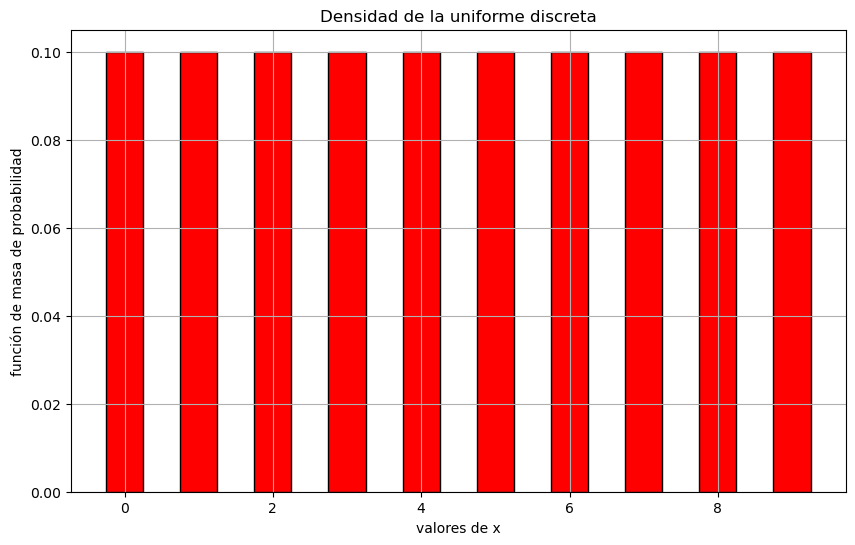

In [ ]:
# Densidad de una uniforme discreta
min = 0
max = 10
x = np.arange(min, max) # dar valores de x

# Vamos a crear la función de masa (pmf (probability mass function))

pmf_unif = np.full_like(x, 1/(max-min), dtype=float) # crea un arreglo del mismo tamaño

# Graficamos
plt.figure(figsize=(10,6))
# grafica de barras
# width (ancho de la barra), edgecolor (color del borde de la barra)
plt.bar(x, pmf_unif, width=0.5, color='r', edgecolor='black')
plt.xlabel('valores de x')
plt.ylabel('función de masa de probabilidad')
plt.title('Densidad de la uniforme discreta')
plt.grid(True)
plt.show()

Para más información sobre los colores en Matplotlib, ver [ColoresMatplotlib](https://matplotlib.org/stable/gallery/color/named_colors.html)

## Variable aleatoria Bernoulli con parámetro $p\in (0,1)$.

El modelo probabilístico Bernoulli se aplica a un experimento cuyo espacio muestral está constituido sólo por dos resultados posibles, éxito y fracaso:

Se considerará una v.a $X$ sobre el espacio muestral $$\Omega=\{\text{éxito, fracaso}\}$$
de tal forma que
* $X(\{\text{éxito}\}) = 1$
* $X(\{\text{fracaso}\}) = 0$

Las probabilidades asociadas a este modelo son:

* $\mathbb{P}(\{\text{éxito}\}) = p$
* $\mathbb{P}(\{\text{fracaso}\}) = 1-p$

donde $0<p<1$.


Entonces la función de densidad de masa de probabilidades de $X$ está dada por:

$$p_{X}(k)=\begin{cases}
p &\quad \text{si } k=1 \\
1-p &\quad \text{si } k=0
\end{cases}$$

**Notación:** $X\sim \text{Ber}(p)$.

Esta variable aleatoria es muy importante. En la practica es usada para modelar situaciones en las cuales hay dos posibles resultados como:
* el estado de un teléfono en un momento dado: libre u ocupado.
* una persona pueda estar enferma o sana de una determinada enfermedad.
* la preferencia de una persona, la cual puede estar a favor o en contra de un candidato determinado.

Mediante la combinación de variables aleatorias Bernoulli es posible construir otras variables aleatorias.

### Esperanza y Varianza

Si $X\sim \text{Ber}(p)$, entonces su esperanza es:
\begin{align*}
\mathbb{E}[X] = \sum_{k=0}^{1}kp_{X}(k) = 1\cdot p + 0\cdot (1-p) = p.
\end{align*}

Y su varianza se calcula usando,
$$\mathbb{E}[X^{2}] = \sum_{k=0}^{1}k^{2}p_{X}(k) = 1^{2}\cdot p + 0^{2}\cdot (1-p) = p.$$
Por lo tanto,
$$\text{Var}(X)=\mathbb{E}[X^{2}]-(\mathbb{E}[X])^{2} = p-p^{2} = p(1-p)$$



La función de densidad es: [0.6 0.4]


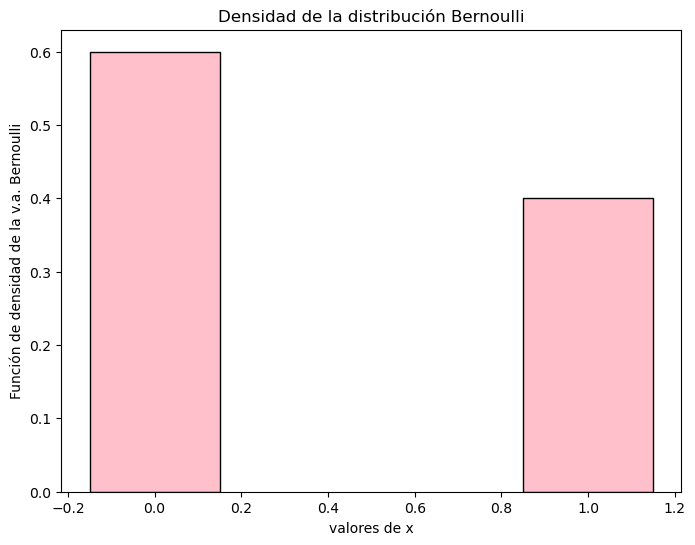

In [ ]:
# Gráfica de la densidad Bernoulli

# Definir mi probabilidad de éxito
p = 0.4

# Defino los posibles valores de la v.a.
x = [0,1]

# Calcular la función de masa
pmf_ber = bernoulli.pmf(x,p)

print("La función de densidad es:", pmf_ber)

plt.figure(figsize=(8,6))
plt.bar(x, pmf_ber, width=0.3, color="pink", edgecolor= "k")
plt.xlabel("valores de x")
plt.ylabel("Función de densidad de la v.a. Bernoulli")
plt.title("Densidad de la distribución Bernoulli")
plt.show()

In [ ]:
media = bernoulli.mean(p)
varianza = bernoulli.var(p)
print("La esperanza es:", media)
print("La varianza es:", varianza)

La esperanza es: 0.4
La varianza es: 0.24


## Variable aleatoria Binomial con parámetros $n$ y $p\in (0,1)$.

Decimos que una v.a $X$ tiene distribución binomial con párametros $n$ y $p$, si su función de densidad de masa de probabilidades está dada por:
$$\begin{equation*}
	p_{X}(k)= \mathbb{P}(X=k)= \begin{cases}
	\binom{n}{k}p^{k}(1-p)^{n-k} &\quad \text{si } k=0,1,\dots,n \\
	\qquad 0 &\quad \text{en otro caso}  
	\end{cases}
\end{equation*}$$
donde $n$ es un entero positivo y $0< p< 1$.

La esperanza de $X$ es:
\begin{align*}
\mathbb{E}[X]&= \sum_{k \mathop = 0}^n k \binom n k p^k (1-p)^{n - k}\\
&=\sum_{k \mathop = 1}^n k \binom n k p^k (1-p)^{n - k}\\
&= \sum_{k \mathop = 1}^n n \binom {n - 1} {k - 1} p^k (1-p)^{n - k}\\
&= n p \sum_{k \mathop = 1}^n \binom {n - 1} {k - 1} p^{k - 1} (1-p)^{( {n - 1}) - ( {k - 1}) }\\
&=n p \sum_{j \mathop = 0}^m \binom m j p^j (1-p)^{m - j}\\
&=np
\end{align*}

Ahora,
\begin{align*}
\mathbb{E}[X^2]&= \sum_{k \mathop = 0}^n k^2 \binom n k p^k (1-p)^{n - k}\\
&=\sum_{k \mathop = 0}^n k n \binom {n - 1} {k - 1} p^k (1-p)^{n - k}\\
&= n p \sum_{k \mathop = 1}^n k \binom {n - 1} {k - 1} p^{k - 1} (1-p)^{({n - 1}) - ({k - 1}) }\\
&= n p \sum_{j \mathop = 0}^m ({j + 1}) \binom m j p^j (1-p)^{m - j}\\
&=n p \left( {\sum_{j \mathop = 0}^m j \binom m j p^j (1-p)^{m - j} + \sum_{j \mathop = 0}^m \binom m j p^j (1-p)^{m - j} }\right)\\
&=n p \left( {\sum_{j \mathop = 0}^m m \binom {m - 1} {j - 1} p^j (1-p)^{m - j} + \sum_{j \mathop = 0}^m \binom m j p^j (1-p)^{m - j} }\right)\\
&= n p \left( (n - 1) p \sum_{j \mathop = 1}^m \binom {m - 1}{j - 1} p^{j - 1} (1-p)^{( {m - 1}) - ({j - 1}) } + \sum_{j \mathop = 0}^m \binom m j p^j (1-p)^{m - j}\right) \\
&= n p \left( (n - 1) p (p + (1-p))^{m - 1} + (p + (1-p))^m\right)\\
&= n p ((n - 1) p + 1)\\
&= (np)^2 +np(1-p),
\end{align*}

por lo que la varianza de $X$ es:
$$\text{Var}(X)=np(1-p).$$

**Ejemplo** Una moneda no justa se tira 6 veces, donde la probabilidad de obtener sol es de $0.3$.

Sea $X$ el número de veces que cae sol, entonces $X$ tiene una distribución binomial con parámetros $n=6$ y $p=0.3$. Por lo que
$$\begin{align*}
\mathbb{P}(X=2) &= \binom{6}{2}(0.3)^{2}(0.7)^{4}=0.3241 \\
\mathbb{P}(X=3) &= \binom{6}{3}(0.3)^{3}(0.7)^{3}=0.1852 \\
\mathbb{P}(1<X\le 5) &= \mathbb{P}(X=2)+\mathbb{P}(X=3)+\mathbb{P}(X=4)+\mathbb{P}(X=5) \\
			&= 0.3241 + 0.1852 + \binom{6}{4}(0.3)^{4}(0.7)^{2} + \binom{6}{5}(0.3)^{5}(0.7)^{1} \\
			&= 0.5093 + 0.0595 + 0.0102 = 0.579
\end{align*}$$

Note que la probabilidad $$\mathbb{P}(1<X\leq 5)=F_{X}(5)-F_{X}(1).$$

Usando el tributo `.cdf `, podemos calcualr la probabilidad anterior:

In [ ]:
# cdf es la cumulative distrubition function

# Probabilidad de que haya 5 o menos éxitos en 6 ensayos
F5 = binom.cdf(5,6,0.3) # x= 5, n=6, p= 0,3

# Probabilidad de que haya 1 o menos éxitos en 6 ensayos
F1 = binom.cdf(1,6,0.3) # x=15, n=6, p= 0,3

In [ ]:
Proba = F5-F1
Proba

np.float64(0.5790960000000003)

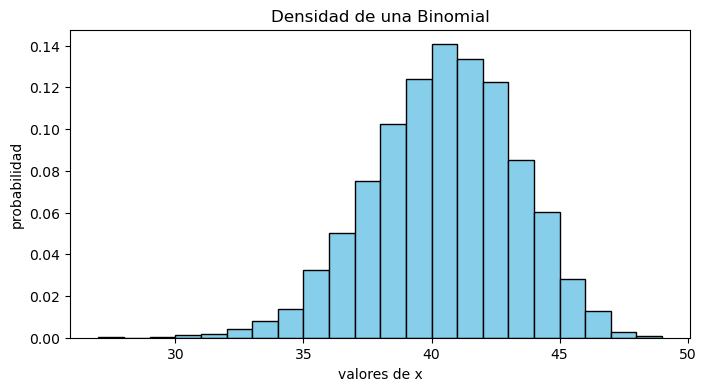

In [ ]:
# Gracicamos la Binomial
# Parámetros
n = 50
p= 0.8
# generamos números aleatorios con distribución binomial
binom_numeros = sps.binom.rvs(n,p,size=10000)

# Creaos un histograma
plt.figure(figsize=(8,4))
plt.hist(
    binom_numeros,
    density = True, #normaliza que sea función de densidad
    bins = len(np.unique(binom_numeros)), # numero de barras
    color = "skyblue",
    edgecolor = "k"
)
plt.xlabel("valores de x")
plt.ylabel("probabilidad")
plt.title("Densidad de una Binomial")
plt.show()

## Variable aleatoria Poisson

Es una distribución de probabilidad discreta que  sirve para calcular la probabilidad de que ocurra un determinado **número de eventos raros** durante un intervalo dado (puede ser de tiempo, longitud, área, etc.

Esta variable aleatoria toma los valores sobre el conjunto $\{0,1,2,\dots\}$ y tiene un parámetro $\lambda>0$, el cual representa el número de veces que se **espera** que ocurra un evento durante un intervalo dado.

La función de masa de probabilidades de una variable aleatoria Poisson, $X$, está dada por:
$$p_{X}(k)=\begin{cases}
	e^{-\lambda}\frac{\lambda^{k}}{k!} &\quad \text{si } k=0,1,2,\dots \\
	0 &\quad \text{en otro caso}  
\end{cases}$$

En efecto, es una función de masa de probabilidades debido a que
$$\begin{align*}
\sum_{k=0}^{\infty}e^{-\lambda}\frac{\lambda^{k}}{k!} &= e^{-\lambda}\sum_{k=0}^{\infty}\frac{\lambda^{k}}{k!} \\ &= e^{-\lambda}\underbrace{\left(1+\lambda+\frac{\lambda^{2}}{2!}+\frac{\lambda^{3}}{3!}+\cdots\right)}_{\text{desarrollo de Taylor de }e^{\lambda}} \\ &= e^{-\lambda}e^{\lambda}=1.
\end{align*}$$

Se tiene que $\mathbb{E}[X] = \lambda$ y $\text{Var}(X)= \lambda$.

**Aplicaciones**

**Ejemplo:** Supongamos que el número de accidentes que ocurre en un punto tiene una distribución Poisson con parámetro $\lambda=2$.
* ¿Cuál es la probabilidad de que en un día ocurran más de dos accidentes?

  $$
  \begin{align*}
  \mathbb{P}(X>2) &= 1-\mathbb{P}(X\le 2) \\ &=1-\left[\mathbb{P}(X=0)+\mathbb{P}(X=1)+\mathbb{P}(X=2)\right] \\ &= 1-\left[\frac{e^{-2}2^{0}}{0!}+\frac{e^{-2}2^{1}}{1!}+\frac{e^{-2}2^{2}}{2!}\right] \\ &= 1-e^{-2}\left[1+2+2\right] = 1-5e^{-2} = 0.3233
  \end{align*}
  $$

* ¿Cuál es la probabilidad de que en un día ocurran más de dos accidentes, sabiendo que ocurre por lo menos uno?
$$\begin{align*}
\mathbb{P}(X>2 \mid X\ge 1) = \frac{\mathbb{P}(X>2 \cap X\ge 1)}{\mathbb{P}(X\ge 1)} = \frac{\mathbb{P}(X>2)}{\mathbb{P}(X\ge 1)} = \frac{1-\mathbb{P}(X\leq 2)}{1-\mathbb{P}(X<1)} = \frac{1-5e^{-2}}{1-e^{-2}} = \frac{0.3233}{0.8646} = 0.3739
\end{align*}$$
ya que $\mathbb{P}(X\ge 1)=1-\mathbb{P}(X<1)=1-\mathbb{P}(X=0)=1-e^{-2}$

Para ver más información, revisar [Poisson](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html)

## Demostración de Esperanza y Varianza para $X \sim \text{Poisson}(\lambda)$:

$$\mathbb{E}[X] = \sum_{k=0}^{\infty} k \, e^{-\lambda}\frac{\lambda^k}{k!} = \lambda e^{-\lambda} \sum_{k=1}^{\infty} \frac{\lambda^{k-1}}{(k-1)!} = \lambda e^{-\lambda} e^{\lambda} = \lambda$$

Calculamos $\mathbb{E}[X(X-1)]$ para obtener la varianza de forma directa:
$$\mathbb{E}[X(X-1)] = \sum_{k=2}^{\infty} k(k-1) e^{-\lambda}\frac{\lambda^k}{k!} = \lambda^2 e^{-\lambda} \sum_{k=2}^{\infty} \frac{\lambda^{k-2}}{(k-2)!} = \lambda^2 e^{-\lambda} e^{\lambda} = \lambda^2$$

Como $\mathbb{E}[X^2] = \mathbb{E}[X(X-1)] + \mathbb{E}[X] = \lambda^2 + \lambda$, concluimos que:

$$\text{Var}(X) = \mathbb{E}[X^2] - (\mathbb{E}[X])^2 = (\lambda^2 + \lambda) - \lambda^2 = \lambda \quad \blacksquare$$

Ahora, vamos a calcular las probabilidades anteriores usando el atributo `.cdf`

$\color{red}{\text{Ejercicio 2.}}$ Utilizar el atributo `.cdf` para verificar los resultados de arriba. Además gráficar la función de densidad de una Poisson.

P(X > 2) =  0.3233
P(X > 2 | X >= 1) =  0.3739


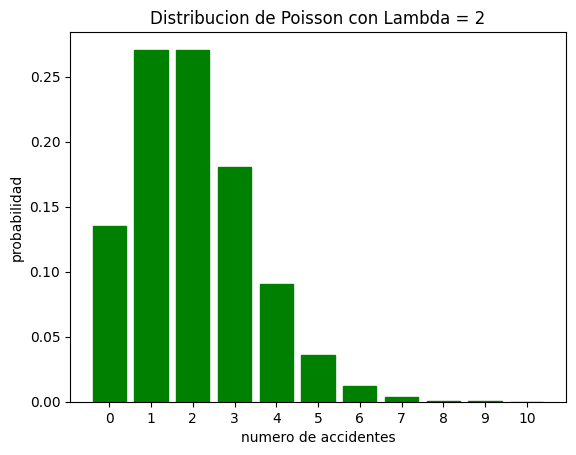

In [ ]:
# Ejercicio POISSON
from scipy.stats import poisson
import numpy as np
import matplotlib.pyplot as plt
# Parametros
mu = 2
accidentes = 2
# Probabilidad de mas de dos accidentes
P1 = 1 - poisson.cdf(accidentes, mu)
print("P(X > 2) = ", round(P1, 4)) # usamos round para redondearlo a 4 decimales
# Probabilidad condicional
P2 = (1 - poisson.cdf(accidentes, mu)) / (1 - poisson.cdf(0, mu))
print("P(X > 2 | X >= 1) = ", round(P2, 4))
# Graficando POISSON
x = np.arange(0,11)
y = poisson.pmf(x, mu)
plt.bar(x, y, color = "green", edgecolor = "green")
plt.xlabel("numero de accidentes")
plt.ylabel("probabilidad")
plt.title("Distribucion de Poisson con Lambda = 2")
plt.xticks(x)
plt.show()